<a href="https://colab.research.google.com/github/Ali010304/metodos-numericos-1/blob/main/DiferenciasDivididas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Coeficientes obtenidos (F_{i,i}): [np.float64(1.0), np.float64(1.2868563172028207), np.float64(1.5495131878877864)]
Polinomio interpolador P(x): 1.54951318788779*x**2 - 2.1995483555447*x + 1.65003516765691


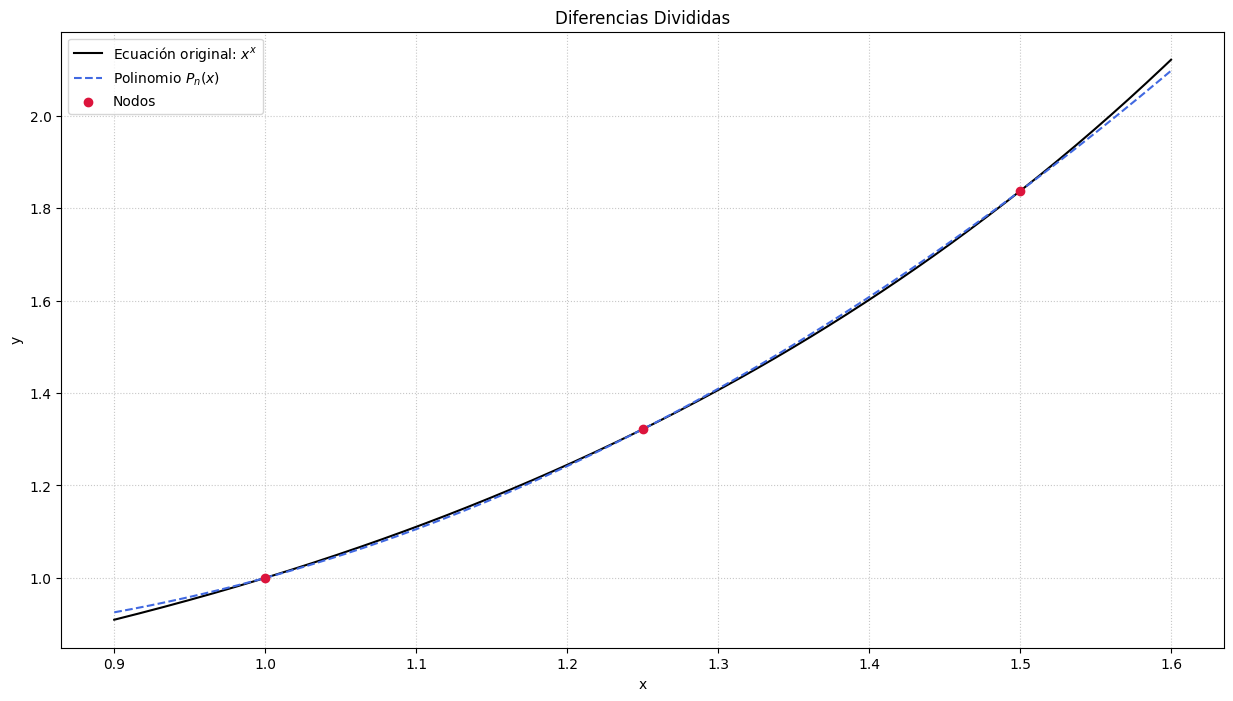

In [8]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp


def diferenias_divididas(x_datos, y_datos):

    n = len(x_datos) - 1
    F = np.zeros((n + 1, n + 1), dtype=float)


    for i in range(n + 1):
        F[i, 0] = y_datos[i]


    for i in range(1, n + 1):
        for j in range(1, i + 1):
            F[i, j] = (F[i, j - 1] - F[i - 1, j - 1]) / (
                x_datos[i] - x_datos[i - j]
            )

    coeficientes = [F[i, i] for i in range(n + 1)]
    return coeficientes



x = sp.Symbol("x")
f_original = x**x

x_nodos = [1.0, 1.25, 1.5]
y_nodos = [float(f_original.subs(x, xi)) for xi in x_nodos]

# =====================================================================
# 2. EJECUCIÓN DEL ALGORITMO 3.2 (Solo devuelve los coeficientes)
# =====================================================================
coefs = algoritmo_3_2_newton(x_nodos, y_nodos)
print("Coeficientes obtenidos (F_{i,i}):", coefs)


# 3. CONSTRUCCIÓN DEL POLINOMIO ENTREGANDO LOS COEFICIENTES A SYMPY
#
# Armamos P_n(x) = F_{0,0} + sum_{i=1}^n F_{i,i} * prod_{j=0}^{i-1} (x - x_)
P_sym = coefs[0]
for i in range(1, len(coefs)):
    producto = 1
    for j in range(i):
        producto *= x - x_nodos[j]
    P_sym += coefs[i] * producto


P_expandido = sp.expand(P_sym)
print("Polinomio interpolador P(x):", P_expandido)


f_num = sp.lambdify(x, f_original, "numpy")
P_num = sp.lambdify(x, P_expandido, "numpy")

x_vals = np.linspace(min(x_nodos) - 0.1, max(x_nodos) + 0.1, 300)

plt.figure(figsize=(15, 8))
plt.plot(
    x_vals,
    f_num(x_vals),
    label=f"Ecuación original: ${sp.latex(f_original)}$",
    color="black",
)
plt.plot(
    x_vals,
    P_num(x_vals),
    label="Polinomio $P_n(x)$",
    color="royalblue",
    linestyle="--",
)
plt.scatter(x_nodos, y_nodos, color="crimson", zorder=5, label="Nodos")

plt.title("Diferencias Divididas")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.7)
plt.show()